In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
!git clone https://github.com/TokaElsaayed/Deep-project.git

Cloning into 'Deep-project'...
remote: Enumerating objects: 216, done.
remote: Counting objects: 100% (67/67), done.
remote: Compressing objects: 100% (54/54), done.
remote: Total 216 (delta 26), reused 34 (delta 13), pack-reused 149 (from 1)
Receiving objects: 100% (216/216), 49.86 MiB | 35.68 MiB/s, done.
Resolving deltas: 100% (56/56), done.


In [2]:
!python src/training/visualize_scratch_resnet.py

python3: can't open file '/kaggle/working/src/training/visualize_scratch_resnet.py': [Errno 2] No such file or directory


In [3]:
!ls

Deep-project


In [5]:
%%writefile /kaggle/working/Deep-project/visualize_scratch_resnet.py

"""Create Kaggle-ready evaluation and Grad-CAM visuals for the scratch ResNet.

Run from the repository root after attaching the dataset/checkpoint:
    python src/training/visualize_scratch_resnet.py

The script evaluates the held-out test split once and writes figures and CSVs
to outputs/scratch_resnet_visualizations. It does not train or select a model.
"""
from __future__ import annotations

import argparse
import json
import sys
from pathlib import Path
from typing import Any

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from torch.utils.data import DataLoader
from torchvision import transforms as T
from tqdm.auto import tqdm

ROOT = Path(__file__).resolve().parents[2]
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from models.scratch_resnet import ScratchResNet  # noqa: E402
from training.train_scratch_resnet import (  # noqa: E402
    CACHE_SIZE, DEFAULT_MEAN, DEFAULT_STD, IMAGE_SIZE, NUM_CLASSES,
    load_splits, load_hf_split, to_pil,
)


def arguments() -> argparse.Namespace:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--split-csv", type=Path, default=ROOT / "outputs/eda/splits.csv")
    parser.add_argument("--checkpoint", type=Path, default=ROOT / "outputs/baseline/best.pth")
    parser.add_argument("--history-csv", type=Path, default=ROOT / "outputs/baseline/history.csv",
                        help="Training history CSV; set to the run that produced the checkpoint.")
    parser.add_argument("--output-dir", type=Path, default=ROOT / "outputs/scratch_resnet_visualizations")
    parser.add_argument("--batch-size", type=int, default=64)
    parser.add_argument("--gradcam-count", type=int, default=16)
    parser.add_argument("--examples-count", type=int, default=20)
    parser.add_argument("--seed", type=int, default=42)
    return parser.parse_args()


def class_names_for(dataset: Any) -> list[str]:
    try:
        names = dataset.features["label"].names
        if len(names) == NUM_CLASSES:
            return [str(name) for name in names]
    except (AttributeError, KeyError, TypeError):
        pass
    return [f"Class {i}" for i in range(NUM_CLASSES)]


def load_test_data(split_csv: Path, batch_size: int, device: torch.device):
    _, _, rows = load_splits(split_csv)
    source = load_hf_split("Multimodal-Fatima/CUB_test", "test")
    resize = T.Compose([T.Resize(CACHE_SIZE), T.CenterCrop(CACHE_SIZE)])
    transform = T.Compose([
        T.CenterCrop(IMAGE_SIZE), T.ToTensor(),
        T.Normalize(mean=DEFAULT_MEAN, std=DEFAULT_STD),
    ])
    images: list[Image.Image] = []
    tensors: list[torch.Tensor] = []
    labels: list[int] = []
    ids: list[str] = []
    for _, row in tqdm(rows.iterrows(), total=len(rows), desc="Preparing test images"):
        raw = to_pil(source[int(row["index"])]["image"])
        image = resize(raw)
        images.append(T.CenterCrop(IMAGE_SIZE)(image))
        tensors.append(transform(image))
        labels.append(int(row["label"]))
        ids.append(str(row.get("id", row["index"])))
    loader = DataLoader(list(zip(tensors, labels)), batch_size=batch_size, shuffle=False,
                        num_workers=0, pin_memory=device.type == "cuda")
    return loader, images, np.asarray(labels), ids, class_names_for(source)


def restore_model(checkpoint_path: Path, device: torch.device):
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f"Checkpoint not found: {checkpoint_path}")
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    if not isinstance(checkpoint, dict) or "model_state_dict" not in checkpoint:
        raise ValueError("Expected the project's checkpoint with a model_state_dict entry.")
    model = ScratchResNet(num_classes=NUM_CLASSES).to(device)
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    model.eval()
    return model, checkpoint


@torch.inference_mode()
def predict(model, loader, device):
    predictions, probabilities = [], []
    for batch, _ in tqdm(loader, desc="Predicting test set"):
        logits = model(batch.to(device, non_blocking=True))
        probs = torch.softmax(logits, dim=1)
        predictions.extend(probs.argmax(1).cpu().tolist())
        probabilities.extend(probs.cpu().numpy())
    return np.asarray(predictions), np.asarray(probabilities)


def save_prediction_examples(images, truths, predictions, probs, ids, names, output: Path, count: int, seed: int):
    rng = np.random.default_rng(seed)
    wrong = np.flatnonzero(truths != predictions)
    right = np.flatnonzero(truths == predictions)
    chosen = list(rng.choice(wrong, min(count // 2, len(wrong)), replace=False)) if len(wrong) else []
    chosen += list(rng.choice(right, min(count - len(chosen), len(right)), replace=False)) if len(right) else []
    if not chosen:
        return
    cols = 4
    rows = int(np.ceil(len(chosen) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows), squeeze=False)
    for axis, index in zip(axes.flat, chosen):
        axis.imshow(images[index])
        correct = truths[index] == predictions[index]
        axis.set_title(
            f"{'Correct' if correct else 'Error'} · {probs[index, predictions[index]]:.1%}\n"
            f"True: {names[truths[index]]}\nPred: {names[predictions[index]]}",
            color="darkgreen" if correct else "darkred", fontsize=9,
        )
        axis.axis("off")
    for axis in axes.flat[len(chosen):]:
        axis.axis("off")
    fig.suptitle("Scratch ResNet test predictions", fontsize=15)
    fig.tight_layout()
    fig.savefig(output / "prediction_examples.png", dpi=160, bbox_inches="tight")
    plt.close(fig)


def gradcam(model, tensor: torch.Tensor, class_index: int, device: torch.device) -> np.ndarray:
    activations: list[torch.Tensor] = []
    gradients: list[torch.Tensor] = []
    layer = model.layers[-1]
    forward_hook = layer.register_forward_hook(lambda _m, _i, out: activations.append(out))
    backward_hook = layer.register_full_backward_hook(lambda _m, _gi, go: gradients.append(go[0]))
    model.zero_grad(set_to_none=True)
    logits = model(tensor.unsqueeze(0).to(device))
    logits[0, class_index].backward()
    forward_hook.remove()
    backward_hook.remove()
    weights = gradients[0].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((weights * activations[0]).sum(dim=1, keepdim=True))
    cam = torch.nn.functional.interpolate(cam, size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear", align_corners=False)
    cam = cam[0, 0].detach().cpu().numpy()
    return cam / (cam.max() + 1e-8)


def save_gradcam_grid(model, images, truths, predictions, tensors, names, output: Path, count: int, device, seed: int):
    if not count:
        return
    rng = np.random.default_rng(seed)
    incorrect = np.flatnonzero(truths != predictions)
    correct = np.flatnonzero(truths == predictions)
    chosen = list(rng.choice(incorrect, min(count // 2, len(incorrect)), replace=False)) if len(incorrect) else []
    chosen += list(rng.choice(correct, min(count - len(chosen), len(correct)), replace=False)) if len(correct) else []
    if not chosen:
        return
    cols = 4
    rows = int(np.ceil(len(chosen) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows), squeeze=False)
    for axis, index in zip(axes.flat, chosen):
        cam = gradcam(model, tensors[index], int(predictions[index]), device)
        original = np.asarray(images[index]).astype(np.float32) / 255
        axis.imshow(original)
        axis.imshow(cam, cmap="jet", alpha=0.42, vmin=0, vmax=1)
        mark = "correct" if truths[index] == predictions[index] else "incorrect"
        axis.set_title(f"Grad-CAM ({mark})\nTrue: {names[truths[index]]}\nPred: {names[predictions[index]]}", fontsize=9)
        axis.axis("off")
    for axis in axes.flat[len(chosen):]:
        axis.axis("off")
    fig.suptitle("Scratch ResNet Grad-CAM · highlighted regions influence the predicted class", fontsize=14)
    fig.tight_layout()
    fig.savefig(output / "gradcam_examples.png", dpi=160, bbox_inches="tight")
    plt.close(fig)


def save_comparison_plot(output: Path) -> None:
    path = ROOT / "outputs/transfer_learning/comparison_with_scratch_resnet.csv"
    if not path.is_file():
        path = ROOT / "outputs/transfer_learning/comparison_all_experiments.csv"
    if not path.is_file():
        return
    frame = pd.read_csv(path)
    frame.columns = [str(column).strip().lower() for column in frame.columns]
    model_col = next((c for c in frame.columns if c in {"model", "model_name"}), None)
    acc_col = next((c for c in frame.columns if c in {"test_accuracy", "standard_test_accuracy"}), None)
    if model_col is None or acc_col is None:
        return
    frame = frame.dropna(subset=[acc_col]).copy()
    if frame.empty:
        return
    frame["is_scratch"] = frame[model_col].astype(str).str.contains("scratch", case=False)
    fig, ax = plt.subplots(figsize=(9, 5))
    colors = ["#2c7fb8" if is_scratch else "#9ecae1" for is_scratch in frame["is_scratch"]]
    bars = ax.bar(frame[model_col].astype(str), frame[acc_col].astype(float) * 100, color=colors)
    ax.bar_label(bars, fmt="%.1f%%", padding=3)
    ax.set_ylabel("Test accuracy (%)")
    ax.set_title("Scratch ResNet and transfer model test accuracy")
    ax.tick_params(axis="x", rotation=20)
    ax.set_ylim(0, min(100, float(frame[acc_col].max()) * 115))
    fig.tight_layout()
    fig.savefig(output / "model_comparison.png", dpi=160, bbox_inches="tight")
    plt.close(fig)


def save_training_curves(history_path: Path, output: Path) -> None:
    if not history_path.is_file():
        print(f"Training history not found; skipping training curves: {history_path}")
        return
    history = pd.read_csv(history_path)
    required = {"epoch", "train_loss", "val_loss", "train_acc", "val_acc"}
    if not required.issubset(history.columns):
        print(f"History is missing expected columns {sorted(required)}; skipping training curves.")
        return
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(history["epoch"], history["train_loss"], label="Train")
    axes[0].plot(history["epoch"], history["val_loss"], label="Validation")
    axes[0].set(title="Loss by epoch", xlabel="Epoch", ylabel="Cross-entropy loss")
    axes[1].plot(history["epoch"], history["train_acc"] * 100, label="Train")
    axes[1].plot(history["epoch"], history["val_acc"] * 100, label="Validation")
    axes[1].set(title="Accuracy by epoch", xlabel="Epoch", ylabel="Accuracy (%)")
    for axis in axes:
        axis.legend()
        axis.grid(alpha=0.2)
    fig.suptitle("Scratch ResNet training history")
    fig.tight_layout()
    fig.savefig(output / "training_curves.png", dpi=160, bbox_inches="tight")
    plt.close(fig)


def main() -> None:
    args = arguments()
    args.output_dir.mkdir(parents=True, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Device: {device}")
    model, checkpoint = restore_model(args.checkpoint, device)
    loader, images, truths, ids, names = load_test_data(args.split_csv, args.batch_size, device)
    predictions, probabilities = predict(model, loader, device)
    confidence = probabilities.max(axis=1)
    output_frame = pd.DataFrame({
        "image_id": ids, "true_label": truths, "true_class": [names[x] for x in truths],
        "predicted_label": predictions, "predicted_class": [names[x] for x in predictions],
        "confidence": confidence, "correct": truths == predictions,
    })
    output_frame.to_csv(args.output_dir / "test_predictions.csv", index=False)
    cm = confusion_matrix(truths, predictions, labels=np.arange(NUM_CLASSES))
    class_accuracy = np.divide(np.diag(cm), cm.sum(axis=1), out=np.zeros(NUM_CLASSES), where=cm.sum(axis=1) > 0)
    pd.DataFrame({"label": np.arange(NUM_CLASSES), "class_name": names,
                  "support": cm.sum(axis=1), "accuracy": class_accuracy}).to_csv(
        args.output_dir / "per_class_accuracy.csv", index=False)
    summary = {
        "model": "scratch_resnet", "checkpoint": str(args.checkpoint),
        "checkpoint_epoch": checkpoint.get("epoch"), "test_images": int(len(truths)),
        "test_accuracy": float(accuracy_score(truths, predictions)),
        "macro_f1": float(f1_score(truths, predictions, average="macro", zero_division=0)),
        "mean_confidence": float(confidence.mean()),
        "gradcam_target_layer": "layers[-1]", "device": str(device),
        "note": "Grad-CAM visualizes evidence for the predicted class; it is qualitative, not causal proof.",
    }
    (args.output_dir / "evaluation_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.hist(confidence, bins=20, color="#4c78a8", edgecolor="white")
    ax.set(title="Scratch ResNet test confidence", xlabel="Maximum predicted probability", ylabel="Images")
    fig.tight_layout(); fig.savefig(args.output_dir / "confidence_distribution.png", dpi=160); plt.close(fig)

    worst = np.argsort(class_accuracy)[:20]
    fig, ax = plt.subplots(figsize=(9, 8))
    ax.barh([names[i] for i in worst][::-1], class_accuracy[worst][::-1] * 100, color="#e07a5f")
    ax.set(title="20 lowest-accuracy test classes", xlabel="Accuracy (%)", xlim=(0, 100))
    fig.tight_layout(); fig.savefig(args.output_dir / "lowest_class_accuracy.png", dpi=160); plt.close(fig)

    # Save a readable confusion heatmap for the 20 classes with most test errors.
    errors_per_class = cm.sum(axis=1) - np.diag(cm)
    focus = np.argsort(errors_per_class)[-20:]
    fig, ax = plt.subplots(figsize=(12, 10))
    heatmap = ax.imshow(cm[np.ix_(focus, focus)], cmap="Blues", aspect="auto")
    ax.set_xticks(np.arange(len(focus)), labels=[names[i] for i in focus])
    ax.set_yticks(np.arange(len(focus)), labels=[names[i] for i in focus])
    fig.colorbar(heatmap, ax=ax, label="Image count")
    ax.set(title="Confusion matrix · 20 classes with most errors", xlabel="Predicted class", ylabel="True class")
    ax.tick_params(axis="x", rotation=90, labelsize=7); ax.tick_params(axis="y", labelsize=7)
    fig.tight_layout(); fig.savefig(args.output_dir / "confusion_matrix_top_errors.png", dpi=160); plt.close(fig)

    save_prediction_examples(images, truths, predictions, probabilities, ids, names,
                             args.output_dir, args.examples_count, args.seed)
    save_gradcam_grid(model, images, truths, predictions, [item[0] for item in loader.dataset],
                      names, args.output_dir, args.gradcam_count, device, args.seed)
    save_comparison_plot(args.output_dir)
    save_training_curves(args.history_csv, args.output_dir)
    print(json.dumps(summary, indent=2))
    print(f"Visualizations and reports saved to: {args.output_dir}")


if __name__ == "__main__":
    main()

Overwriting /kaggle/working/Deep-project/visualize_scratch_resnet.py


In [3]:
!ls /kaggle/working
!ls /kaggle/working/Deep-project

ls: cannot access '/kaggle/working/Deep-project': No such file or directory


In [4]:
%cd /kaggle/working
!git clone https://github.com/TokaElsaayed/Deep-project.git Deep-project
!ls /kaggle/working/Deep-project

/kaggle/working
Cloning into 'Deep-project'...
remote: Enumerating objects: 216, done.
remote: Counting objects: 100% (67/67), done.
remote: Compressing objects: 100% (54/54), done.
remote: Total 216 (delta 26), reused 34 (delta 13), pack-reused 149 (from 1)
Receiving objects: 100% (216/216), 49.86 MiB | 37.88 MiB/s, done.
Resolving deltas: 100% (56/56), done.
configs			  notebooks	    src
DLproj.ipynb		  outputs	    tests
HYPERPARAMETER_TUNING.md  README.md	    TRANSFER_LEARNING.md
notebook0ce43d1600.ipynb  requirements.txt


In [5]:
%%writefile /kaggle/working/Deep-project/visualize_scratch_resnet.py

"""Create Kaggle-ready evaluation and Grad-CAM visuals for the scratch ResNet.

Run from the repository root after attaching the dataset/checkpoint:
    python src/training/visualize_scratch_resnet.py

The script evaluates the held-out test split once and writes figures and CSVs
to outputs/scratch_resnet_visualizations. It does not train or select a model.
"""
from __future__ import annotations

import argparse
import json
import sys
from pathlib import Path
from typing import Any

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from torch.utils.data import DataLoader
from torchvision import transforms as T
from tqdm.auto import tqdm

ROOT = Path(__file__).resolve().parents[2]
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from models.scratch_resnet import ScratchResNet  # noqa: E402
from training.train_scratch_resnet import (  # noqa: E402
    CACHE_SIZE, DEFAULT_MEAN, DEFAULT_STD, IMAGE_SIZE, NUM_CLASSES,
    load_splits, load_hf_split, to_pil,
)


def arguments() -> argparse.Namespace:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--split-csv", type=Path, default=ROOT / "outputs/eda/splits.csv")
    parser.add_argument("--checkpoint", type=Path, default=ROOT / "outputs/baseline/best.pth")
    parser.add_argument("--history-csv", type=Path, default=ROOT / "outputs/baseline/history.csv",
                        help="Training history CSV; set to the run that produced the checkpoint.")
    parser.add_argument("--output-dir", type=Path, default=ROOT / "outputs/scratch_resnet_visualizations")
    parser.add_argument("--batch-size", type=int, default=64)
    parser.add_argument("--gradcam-count", type=int, default=16)
    parser.add_argument("--examples-count", type=int, default=20)
    parser.add_argument("--seed", type=int, default=42)
    return parser.parse_args()


def class_names_for(dataset: Any) -> list[str]:
    try:
        names = dataset.features["label"].names
        if len(names) == NUM_CLASSES:
            return [str(name) for name in names]
    except (AttributeError, KeyError, TypeError):
        pass
    return [f"Class {i}" for i in range(NUM_CLASSES)]


def load_test_data(split_csv: Path, batch_size: int, device: torch.device):
    _, _, rows = load_splits(split_csv)
    source = load_hf_split("Multimodal-Fatima/CUB_test", "test")
    resize = T.Compose([T.Resize(CACHE_SIZE), T.CenterCrop(CACHE_SIZE)])
    transform = T.Compose([
        T.CenterCrop(IMAGE_SIZE), T.ToTensor(),
        T.Normalize(mean=DEFAULT_MEAN, std=DEFAULT_STD),
    ])
    images: list[Image.Image] = []
    tensors: list[torch.Tensor] = []
    labels: list[int] = []
    ids: list[str] = []
    for _, row in tqdm(rows.iterrows(), total=len(rows), desc="Preparing test images"):
        raw = to_pil(source[int(row["index"])]["image"])
        image = resize(raw)
        images.append(T.CenterCrop(IMAGE_SIZE)(image))
        tensors.append(transform(image))
        labels.append(int(row["label"]))
        ids.append(str(row.get("id", row["index"])))
    loader = DataLoader(list(zip(tensors, labels)), batch_size=batch_size, shuffle=False,
                        num_workers=0, pin_memory=device.type == "cuda")
    return loader, images, np.asarray(labels), ids, class_names_for(source)


def restore_model(checkpoint_path: Path, device: torch.device):
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f"Checkpoint not found: {checkpoint_path}")
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    if not isinstance(checkpoint, dict) or "model_state_dict" not in checkpoint:
        raise ValueError("Expected the project's checkpoint with a model_state_dict entry.")
    model = ScratchResNet(num_classes=NUM_CLASSES).to(device)
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    model.eval()
    return model, checkpoint


@torch.inference_mode()
def predict(model, loader, device):
    predictions, probabilities = [], []
    for batch, _ in tqdm(loader, desc="Predicting test set"):
        logits = model(batch.to(device, non_blocking=True))
        probs = torch.softmax(logits, dim=1)
        predictions.extend(probs.argmax(1).cpu().tolist())
        probabilities.extend(probs.cpu().numpy())
    return np.asarray(predictions), np.asarray(probabilities)


def save_prediction_examples(images, truths, predictions, probs, ids, names, output: Path, count: int, seed: int):
    rng = np.random.default_rng(seed)
    wrong = np.flatnonzero(truths != predictions)
    right = np.flatnonzero(truths == predictions)
    chosen = list(rng.choice(wrong, min(count // 2, len(wrong)), replace=False)) if len(wrong) else []
    chosen += list(rng.choice(right, min(count - len(chosen), len(right)), replace=False)) if len(right) else []
    if not chosen:
        return
    cols = 4
    rows = int(np.ceil(len(chosen) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows), squeeze=False)
    for axis, index in zip(axes.flat, chosen):
        axis.imshow(images[index])
        correct = truths[index] == predictions[index]
        axis.set_title(
            f"{'Correct' if correct else 'Error'} · {probs[index, predictions[index]]:.1%}\n"
            f"True: {names[truths[index]]}\nPred: {names[predictions[index]]}",
            color="darkgreen" if correct else "darkred", fontsize=9,
        )
        axis.axis("off")
    for axis in axes.flat[len(chosen):]:
        axis.axis("off")
    fig.suptitle("Scratch ResNet test predictions", fontsize=15)
    fig.tight_layout()
    fig.savefig(output / "prediction_examples.png", dpi=160, bbox_inches="tight")
    plt.close(fig)


def gradcam(model, tensor: torch.Tensor, class_index: int, device: torch.device) -> np.ndarray:
    activations: list[torch.Tensor] = []
    gradients: list[torch.Tensor] = []
    layer = model.layers[-1]
    forward_hook = layer.register_forward_hook(lambda _m, _i, out: activations.append(out))
    backward_hook = layer.register_full_backward_hook(lambda _m, _gi, go: gradients.append(go[0]))
    model.zero_grad(set_to_none=True)
    logits = model(tensor.unsqueeze(0).to(device))
    logits[0, class_index].backward()
    forward_hook.remove()
    backward_hook.remove()
    weights = gradients[0].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((weights * activations[0]).sum(dim=1, keepdim=True))
    cam = torch.nn.functional.interpolate(cam, size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear", align_corners=False)
    cam = cam[0, 0].detach().cpu().numpy()
    return cam / (cam.max() + 1e-8)


def save_gradcam_grid(model, images, truths, predictions, tensors, names, output: Path, count: int, device, seed: int):
    if not count:
        return
    rng = np.random.default_rng(seed)
    incorrect = np.flatnonzero(truths != predictions)
    correct = np.flatnonzero(truths == predictions)
    chosen = list(rng.choice(incorrect, min(count // 2, len(incorrect)), replace=False)) if len(incorrect) else []
    chosen += list(rng.choice(correct, min(count - len(chosen), len(correct)), replace=False)) if len(correct) else []
    if not chosen:
        return
    cols = 4
    rows = int(np.ceil(len(chosen) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows), squeeze=False)
    for axis, index in zip(axes.flat, chosen):
        cam = gradcam(model, tensors[index], int(predictions[index]), device)
        original = np.asarray(images[index]).astype(np.float32) / 255
        axis.imshow(original)
        axis.imshow(cam, cmap="jet", alpha=0.42, vmin=0, vmax=1)
        mark = "correct" if truths[index] == predictions[index] else "incorrect"
        axis.set_title(f"Grad-CAM ({mark})\nTrue: {names[truths[index]]}\nPred: {names[predictions[index]]}", fontsize=9)
        axis.axis("off")
    for axis in axes.flat[len(chosen):]:
        axis.axis("off")
    fig.suptitle("Scratch ResNet Grad-CAM · highlighted regions influence the predicted class", fontsize=14)
    fig.tight_layout()
    fig.savefig(output / "gradcam_examples.png", dpi=160, bbox_inches="tight")
    plt.close(fig)


def save_comparison_plot(output: Path) -> None:
    path = ROOT / "outputs/transfer_learning/comparison_with_scratch_resnet.csv"
    if not path.is_file():
        path = ROOT / "outputs/transfer_learning/comparison_all_experiments.csv"
    if not path.is_file():
        return
    frame = pd.read_csv(path)
    frame.columns = [str(column).strip().lower() for column in frame.columns]
    model_col = next((c for c in frame.columns if c in {"model", "model_name"}), None)
    acc_col = next((c for c in frame.columns if c in {"test_accuracy", "standard_test_accuracy"}), None)
    if model_col is None or acc_col is None:
        return
    frame = frame.dropna(subset=[acc_col]).copy()
    if frame.empty:
        return
    frame["is_scratch"] = frame[model_col].astype(str).str.contains("scratch", case=False)
    fig, ax = plt.subplots(figsize=(9, 5))
    colors = ["#2c7fb8" if is_scratch else "#9ecae1" for is_scratch in frame["is_scratch"]]
    bars = ax.bar(frame[model_col].astype(str), frame[acc_col].astype(float) * 100, color=colors)
    ax.bar_label(bars, fmt="%.1f%%", padding=3)
    ax.set_ylabel("Test accuracy (%)")
    ax.set_title("Scratch ResNet and transfer model test accuracy")
    ax.tick_params(axis="x", rotation=20)
    ax.set_ylim(0, min(100, float(frame[acc_col].max()) * 115))
    fig.tight_layout()
    fig.savefig(output / "model_comparison.png", dpi=160, bbox_inches="tight")
    plt.close(fig)


def save_training_curves(history_path: Path, output: Path) -> None:
    if not history_path.is_file():
        print(f"Training history not found; skipping training curves: {history_path}")
        return
    history = pd.read_csv(history_path)
    required = {"epoch", "train_loss", "val_loss", "train_acc", "val_acc"}
    if not required.issubset(history.columns):
        print(f"History is missing expected columns {sorted(required)}; skipping training curves.")
        return
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(history["epoch"], history["train_loss"], label="Train")
    axes[0].plot(history["epoch"], history["val_loss"], label="Validation")
    axes[0].set(title="Loss by epoch", xlabel="Epoch", ylabel="Cross-entropy loss")
    axes[1].plot(history["epoch"], history["train_acc"] * 100, label="Train")
    axes[1].plot(history["epoch"], history["val_acc"] * 100, label="Validation")
    axes[1].set(title="Accuracy by epoch", xlabel="Epoch", ylabel="Accuracy (%)")
    for axis in axes:
        axis.legend()
        axis.grid(alpha=0.2)
    fig.suptitle("Scratch ResNet training history")
    fig.tight_layout()
    fig.savefig(output / "training_curves.png", dpi=160, bbox_inches="tight")
    plt.close(fig)


def main() -> None:
    args = arguments()
    args.output_dir.mkdir(parents=True, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Device: {device}")
    model, checkpoint = restore_model(args.checkpoint, device)
    loader, images, truths, ids, names = load_test_data(args.split_csv, args.batch_size, device)
    predictions, probabilities = predict(model, loader, device)
    confidence = probabilities.max(axis=1)
    output_frame = pd.DataFrame({
        "image_id": ids, "true_label": truths, "true_class": [names[x] for x in truths],
        "predicted_label": predictions, "predicted_class": [names[x] for x in predictions],
        "confidence": confidence, "correct": truths == predictions,
    })
    output_frame.to_csv(args.output_dir / "test_predictions.csv", index=False)
    cm = confusion_matrix(truths, predictions, labels=np.arange(NUM_CLASSES))
    class_accuracy = np.divide(np.diag(cm), cm.sum(axis=1), out=np.zeros(NUM_CLASSES), where=cm.sum(axis=1) > 0)
    pd.DataFrame({"label": np.arange(NUM_CLASSES), "class_name": names,
                  "support": cm.sum(axis=1), "accuracy": class_accuracy}).to_csv(
        args.output_dir / "per_class_accuracy.csv", index=False)
    summary = {
        "model": "scratch_resnet", "checkpoint": str(args.checkpoint),
        "checkpoint_epoch": checkpoint.get("epoch"), "test_images": int(len(truths)),
        "test_accuracy": float(accuracy_score(truths, predictions)),
        "macro_f1": float(f1_score(truths, predictions, average="macro", zero_division=0)),
        "mean_confidence": float(confidence.mean()),
        "gradcam_target_layer": "layers[-1]", "device": str(device),
        "note": "Grad-CAM visualizes evidence for the predicted class; it is qualitative, not causal proof.",
    }
    (args.output_dir / "evaluation_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.hist(confidence, bins=20, color="#4c78a8", edgecolor="white")
    ax.set(title="Scratch ResNet test confidence", xlabel="Maximum predicted probability", ylabel="Images")
    fig.tight_layout(); fig.savefig(args.output_dir / "confidence_distribution.png", dpi=160); plt.close(fig)

    worst = np.argsort(class_accuracy)[:20]
    fig, ax = plt.subplots(figsize=(9, 8))
    ax.barh([names[i] for i in worst][::-1], class_accuracy[worst][::-1] * 100, color="#e07a5f")
    ax.set(title="20 lowest-accuracy test classes", xlabel="Accuracy (%)", xlim=(0, 100))
    fig.tight_layout(); fig.savefig(args.output_dir / "lowest_class_accuracy.png", dpi=160); plt.close(fig)

    # Save a readable confusion heatmap for the 20 classes with most test errors.
    errors_per_class = cm.sum(axis=1) - np.diag(cm)
    focus = np.argsort(errors_per_class)[-20:]
    fig, ax = plt.subplots(figsize=(12, 10))
    heatmap = ax.imshow(cm[np.ix_(focus, focus)], cmap="Blues", aspect="auto")
    ax.set_xticks(np.arange(len(focus)), labels=[names[i] for i in focus])
    ax.set_yticks(np.arange(len(focus)), labels=[names[i] for i in focus])
    fig.colorbar(heatmap, ax=ax, label="Image count")
    ax.set(title="Confusion matrix · 20 classes with most errors", xlabel="Predicted class", ylabel="True class")
    ax.tick_params(axis="x", rotation=90, labelsize=7); ax.tick_params(axis="y", labelsize=7)
    fig.tight_layout(); fig.savefig(args.output_dir / "confusion_matrix_top_errors.png", dpi=160); plt.close(fig)

    save_prediction_examples(images, truths, predictions, probabilities, ids, names,
                             args.output_dir, args.examples_count, args.seed)
    save_gradcam_grid(model, images, truths, predictions, [item[0] for item in loader.dataset],
                      names, args.output_dir, args.gradcam_count, device, args.seed)
    save_comparison_plot(args.output_dir)
    save_training_curves(args.history_csv, args.output_dir)
    print(json.dumps(summary, indent=2))
    print(f"Visualizations and reports saved to: {args.output_dir}")


if __name__ == "__main__":
    main()

Writing /kaggle/working/Deep-project/visualize_scratch_resnet.py


In [6]:
%%writefile /kaggle/working/Deep-project/src/training/visualize_scratch_resnet.py

"""Create Kaggle-ready evaluation and Grad-CAM visuals for the scratch ResNet.

Run from the repository root after attaching the dataset/checkpoint:
    python src/training/visualize_scratch_resnet.py

The script evaluates the held-out test split once and writes figures and CSVs
to outputs/scratch_resnet_visualizations. It does not train or select a model.
"""
from __future__ import annotations

import argparse
import json
import sys
from pathlib import Path
from typing import Any

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from torch.utils.data import DataLoader
from torchvision import transforms as T
from tqdm.auto import tqdm

ROOT = Path(__file__).resolve().parents[2]
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from models.scratch_resnet import ScratchResNet  # noqa: E402
from training.train_scratch_resnet import (  # noqa: E402
    CACHE_SIZE, DEFAULT_MEAN, DEFAULT_STD, IMAGE_SIZE, NUM_CLASSES,
    load_splits, load_hf_split, to_pil,
)


def arguments() -> argparse.Namespace:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--split-csv", type=Path, default=ROOT / "outputs/eda/splits.csv")
    parser.add_argument("--checkpoint", type=Path, default=ROOT / "outputs/baseline/best.pth")
    parser.add_argument("--history-csv", type=Path, default=ROOT / "outputs/baseline/history.csv",
                        help="Training history CSV; set to the run that produced the checkpoint.")
    parser.add_argument("--output-dir", type=Path, default=ROOT / "outputs/scratch_resnet_visualizations")
    parser.add_argument("--batch-size", type=int, default=64)
    parser.add_argument("--gradcam-count", type=int, default=16)
    parser.add_argument("--examples-count", type=int, default=20)
    parser.add_argument("--seed", type=int, default=42)
    return parser.parse_args()


def class_names_for(dataset: Any) -> list[str]:
    try:
        names = dataset.features["label"].names
        if len(names) == NUM_CLASSES:
            return [str(name) for name in names]
    except (AttributeError, KeyError, TypeError):
        pass
    return [f"Class {i}" for i in range(NUM_CLASSES)]


def load_test_data(split_csv: Path, batch_size: int, device: torch.device):
    _, _, rows = load_splits(split_csv)
    source = load_hf_split("Multimodal-Fatima/CUB_test", "test")
    resize = T.Compose([T.Resize(CACHE_SIZE), T.CenterCrop(CACHE_SIZE)])
    transform = T.Compose([
        T.CenterCrop(IMAGE_SIZE), T.ToTensor(),
        T.Normalize(mean=DEFAULT_MEAN, std=DEFAULT_STD),
    ])
    images: list[Image.Image] = []
    tensors: list[torch.Tensor] = []
    labels: list[int] = []
    ids: list[str] = []
    for _, row in tqdm(rows.iterrows(), total=len(rows), desc="Preparing test images"):
        raw = to_pil(source[int(row["index"])]["image"])
        image = resize(raw)
        images.append(T.CenterCrop(IMAGE_SIZE)(image))
        tensors.append(transform(image))
        labels.append(int(row["label"]))
        ids.append(str(row.get("id", row["index"])))
    loader = DataLoader(list(zip(tensors, labels)), batch_size=batch_size, shuffle=False,
                        num_workers=0, pin_memory=device.type == "cuda")
    return loader, images, np.asarray(labels), ids, class_names_for(source)


def restore_model(checkpoint_path: Path, device: torch.device):
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f"Checkpoint not found: {checkpoint_path}")
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    if not isinstance(checkpoint, dict) or "model_state_dict" not in checkpoint:
        raise ValueError("Expected the project's checkpoint with a model_state_dict entry.")
    model = ScratchResNet(num_classes=NUM_CLASSES).to(device)
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    model.eval()
    return model, checkpoint


@torch.inference_mode()
def predict(model, loader, device):
    predictions, probabilities = [], []
    for batch, _ in tqdm(loader, desc="Predicting test set"):
        logits = model(batch.to(device, non_blocking=True))
        probs = torch.softmax(logits, dim=1)
        predictions.extend(probs.argmax(1).cpu().tolist())
        probabilities.extend(probs.cpu().numpy())
    return np.asarray(predictions), np.asarray(probabilities)


def save_prediction_examples(images, truths, predictions, probs, ids, names, output: Path, count: int, seed: int):
    rng = np.random.default_rng(seed)
    wrong = np.flatnonzero(truths != predictions)
    right = np.flatnonzero(truths == predictions)
    chosen = list(rng.choice(wrong, min(count // 2, len(wrong)), replace=False)) if len(wrong) else []
    chosen += list(rng.choice(right, min(count - len(chosen), len(right)), replace=False)) if len(right) else []
    if not chosen:
        return
    cols = 4
    rows = int(np.ceil(len(chosen) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows), squeeze=False)
    for axis, index in zip(axes.flat, chosen):
        axis.imshow(images[index])
        correct = truths[index] == predictions[index]
        axis.set_title(
            f"{'Correct' if correct else 'Error'} · {probs[index, predictions[index]]:.1%}\n"
            f"True: {names[truths[index]]}\nPred: {names[predictions[index]]}",
            color="darkgreen" if correct else "darkred", fontsize=9,
        )
        axis.axis("off")
    for axis in axes.flat[len(chosen):]:
        axis.axis("off")
    fig.suptitle("Scratch ResNet test predictions", fontsize=15)
    fig.tight_layout()
    fig.savefig(output / "prediction_examples.png", dpi=160, bbox_inches="tight")
    plt.close(fig)


def gradcam(model, tensor: torch.Tensor, class_index: int, device: torch.device) -> np.ndarray:
    activations: list[torch.Tensor] = []
    gradients: list[torch.Tensor] = []
    layer = model.layers[-1]
    forward_hook = layer.register_forward_hook(lambda _m, _i, out: activations.append(out))
    backward_hook = layer.register_full_backward_hook(lambda _m, _gi, go: gradients.append(go[0]))
    model.zero_grad(set_to_none=True)
    logits = model(tensor.unsqueeze(0).to(device))
    logits[0, class_index].backward()
    forward_hook.remove()
    backward_hook.remove()
    weights = gradients[0].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((weights * activations[0]).sum(dim=1, keepdim=True))
    cam = torch.nn.functional.interpolate(cam, size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear", align_corners=False)
    cam = cam[0, 0].detach().cpu().numpy()
    return cam / (cam.max() + 1e-8)


def save_gradcam_grid(model, images, truths, predictions, tensors, names, output: Path, count: int, device, seed: int):
    if not count:
        return
    rng = np.random.default_rng(seed)
    incorrect = np.flatnonzero(truths != predictions)
    correct = np.flatnonzero(truths == predictions)
    chosen = list(rng.choice(incorrect, min(count // 2, len(incorrect)), replace=False)) if len(incorrect) else []
    chosen += list(rng.choice(correct, min(count - len(chosen), len(correct)), replace=False)) if len(correct) else []
    if not chosen:
        return
    cols = 4
    rows = int(np.ceil(len(chosen) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows), squeeze=False)
    for axis, index in zip(axes.flat, chosen):
        cam = gradcam(model, tensors[index], int(predictions[index]), device)
        original = np.asarray(images[index]).astype(np.float32) / 255
        axis.imshow(original)
        axis.imshow(cam, cmap="jet", alpha=0.42, vmin=0, vmax=1)
        mark = "correct" if truths[index] == predictions[index] else "incorrect"
        axis.set_title(f"Grad-CAM ({mark})\nTrue: {names[truths[index]]}\nPred: {names[predictions[index]]}", fontsize=9)
        axis.axis("off")
    for axis in axes.flat[len(chosen):]:
        axis.axis("off")
    fig.suptitle("Scratch ResNet Grad-CAM · highlighted regions influence the predicted class", fontsize=14)
    fig.tight_layout()
    fig.savefig(output / "gradcam_examples.png", dpi=160, bbox_inches="tight")
    plt.close(fig)


def save_comparison_plot(output: Path) -> None:
    path = ROOT / "outputs/transfer_learning/comparison_with_scratch_resnet.csv"
    if not path.is_file():
        path = ROOT / "outputs/transfer_learning/comparison_all_experiments.csv"
    if not path.is_file():
        return
    frame = pd.read_csv(path)
    frame.columns = [str(column).strip().lower() for column in frame.columns]
    model_col = next((c for c in frame.columns if c in {"model", "model_name"}), None)
    acc_col = next((c for c in frame.columns if c in {"test_accuracy", "standard_test_accuracy"}), None)
    if model_col is None or acc_col is None:
        return
    frame = frame.dropna(subset=[acc_col]).copy()
    if frame.empty:
        return
    frame["is_scratch"] = frame[model_col].astype(str).str.contains("scratch", case=False)
    fig, ax = plt.subplots(figsize=(9, 5))
    colors = ["#2c7fb8" if is_scratch else "#9ecae1" for is_scratch in frame["is_scratch"]]
    bars = ax.bar(frame[model_col].astype(str), frame[acc_col].astype(float) * 100, color=colors)
    ax.bar_label(bars, fmt="%.1f%%", padding=3)
    ax.set_ylabel("Test accuracy (%)")
    ax.set_title("Scratch ResNet and transfer model test accuracy")
    ax.tick_params(axis="x", rotation=20)
    ax.set_ylim(0, min(100, float(frame[acc_col].max()) * 115))
    fig.tight_layout()
    fig.savefig(output / "model_comparison.png", dpi=160, bbox_inches="tight")
    plt.close(fig)


def save_training_curves(history_path: Path, output: Path) -> None:
    if not history_path.is_file():
        print(f"Training history not found; skipping training curves: {history_path}")
        return
    history = pd.read_csv(history_path)
    required = {"epoch", "train_loss", "val_loss", "train_acc", "val_acc"}
    if not required.issubset(history.columns):
        print(f"History is missing expected columns {sorted(required)}; skipping training curves.")
        return
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(history["epoch"], history["train_loss"], label="Train")
    axes[0].plot(history["epoch"], history["val_loss"], label="Validation")
    axes[0].set(title="Loss by epoch", xlabel="Epoch", ylabel="Cross-entropy loss")
    axes[1].plot(history["epoch"], history["train_acc"] * 100, label="Train")
    axes[1].plot(history["epoch"], history["val_acc"] * 100, label="Validation")
    axes[1].set(title="Accuracy by epoch", xlabel="Epoch", ylabel="Accuracy (%)")
    for axis in axes:
        axis.legend()
        axis.grid(alpha=0.2)
    fig.suptitle("Scratch ResNet training history")
    fig.tight_layout()
    fig.savefig(output / "training_curves.png", dpi=160, bbox_inches="tight")
    plt.close(fig)


def main() -> None:
    args = arguments()
    args.output_dir.mkdir(parents=True, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Device: {device}")
    model, checkpoint = restore_model(args.checkpoint, device)
    loader, images, truths, ids, names = load_test_data(args.split_csv, args.batch_size, device)
    predictions, probabilities = predict(model, loader, device)
    confidence = probabilities.max(axis=1)
    output_frame = pd.DataFrame({
        "image_id": ids, "true_label": truths, "true_class": [names[x] for x in truths],
        "predicted_label": predictions, "predicted_class": [names[x] for x in predictions],
        "confidence": confidence, "correct": truths == predictions,
    })
    output_frame.to_csv(args.output_dir / "test_predictions.csv", index=False)
    cm = confusion_matrix(truths, predictions, labels=np.arange(NUM_CLASSES))
    class_accuracy = np.divide(np.diag(cm), cm.sum(axis=1), out=np.zeros(NUM_CLASSES), where=cm.sum(axis=1) > 0)
    pd.DataFrame({"label": np.arange(NUM_CLASSES), "class_name": names,
                  "support": cm.sum(axis=1), "accuracy": class_accuracy}).to_csv(
        args.output_dir / "per_class_accuracy.csv", index=False)
    summary = {
        "model": "scratch_resnet", "checkpoint": str(args.checkpoint),
        "checkpoint_epoch": checkpoint.get("epoch"), "test_images": int(len(truths)),
        "test_accuracy": float(accuracy_score(truths, predictions)),
        "macro_f1": float(f1_score(truths, predictions, average="macro", zero_division=0)),
        "mean_confidence": float(confidence.mean()),
        "gradcam_target_layer": "layers[-1]", "device": str(device),
        "note": "Grad-CAM visualizes evidence for the predicted class; it is qualitative, not causal proof.",
    }
    (args.output_dir / "evaluation_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.hist(confidence, bins=20, color="#4c78a8", edgecolor="white")
    ax.set(title="Scratch ResNet test confidence", xlabel="Maximum predicted probability", ylabel="Images")
    fig.tight_layout(); fig.savefig(args.output_dir / "confidence_distribution.png", dpi=160); plt.close(fig)

    worst = np.argsort(class_accuracy)[:20]
    fig, ax = plt.subplots(figsize=(9, 8))
    ax.barh([names[i] for i in worst][::-1], class_accuracy[worst][::-1] * 100, color="#e07a5f")
    ax.set(title="20 lowest-accuracy test classes", xlabel="Accuracy (%)", xlim=(0, 100))
    fig.tight_layout(); fig.savefig(args.output_dir / "lowest_class_accuracy.png", dpi=160); plt.close(fig)

    # Save a readable confusion heatmap for the 20 classes with most test errors.
    errors_per_class = cm.sum(axis=1) - np.diag(cm)
    focus = np.argsort(errors_per_class)[-20:]
    fig, ax = plt.subplots(figsize=(12, 10))
    heatmap = ax.imshow(cm[np.ix_(focus, focus)], cmap="Blues", aspect="auto")
    ax.set_xticks(np.arange(len(focus)), labels=[names[i] for i in focus])
    ax.set_yticks(np.arange(len(focus)), labels=[names[i] for i in focus])
    fig.colorbar(heatmap, ax=ax, label="Image count")
    ax.set(title="Confusion matrix · 20 classes with most errors", xlabel="Predicted class", ylabel="True class")
    ax.tick_params(axis="x", rotation=90, labelsize=7); ax.tick_params(axis="y", labelsize=7)
    fig.tight_layout(); fig.savefig(args.output_dir / "confusion_matrix_top_errors.png", dpi=160); plt.close(fig)

    save_prediction_examples(images, truths, predictions, probabilities, ids, names,
                             args.output_dir, args.examples_count, args.seed)
    save_gradcam_grid(model, images, truths, predictions, [item[0] for item in loader.dataset],
                      names, args.output_dir, args.gradcam_count, device, args.seed)
    save_comparison_plot(args.output_dir)
    save_training_curves(args.history_csv, args.output_dir)
    print(json.dumps(summary, indent=2))
    print(f"Visualizations and reports saved to: {args.output_dir}")


if __name__ == "__main__":
    main()

Writing /kaggle/working/Deep-project/src/training/visualize_scratch_resnet.py


In [7]:
!ls /kaggle/working/Deep-project/src/models
!ls /kaggle/working/Deep-project/src/training

scratch_resnet.py  transfer_learning.py
train_scratch_resnet.py  tune_scratch_resnet.py
transfer_learning.py	 visualize_scratch_resnet.py


In [8]:
%cd /kaggle/working/Deep-project
!python src/training/visualize_scratch_resnet.py


/kaggle/working/Deep-project
Device: cuda
Loading dataset 'Multimodal-Fatima/CUB_test', split='test' ...
README.md: 100%|███████████████████████████| 7.15k/7.15k [00:00<00:00, 13.1MB/s]

data/test-00000-of-00002-32b23bf2f7b849a(…): downloading bytes: ▉|  250MB, 20.4M
data/test-00000-of-00002-32b23bf2f7b849a(…): downloading bytes: █|  277MB, 26.0M
data/test-00000-of-00002-32b23bf2f7b849a(…): reconstructing file: 100%|█|  279MB

data/test-00001-of-00002-3cd446126954ca1(…): downloading bytes: ▊|  244MB, 18.5M
data/test-00001-of-00002-3cd446126954ca1(…): reconstructing file:  23%|▏| 67.1MB
data/test-00001-of-00002-3cd446126954ca1(…): downloading bytes: █|  284MB, 26.7M
data/test-00001-of-00002-3cd446126954ca1(…): reconstructing file: 100%|█|  286MB
Predicting test set: 100%|██████████████████████| 91/91 [00:23<00:00,  3.86it/s]
{
  "model": "scratch_resnet",
  "checkpoint": "/kaggle/working/Deep-project/outputs/baseline/best.pth",
  "checkpoint_epoch": 91,
  "test_images": 5794,
  "test_ac

confidence_distribution.png


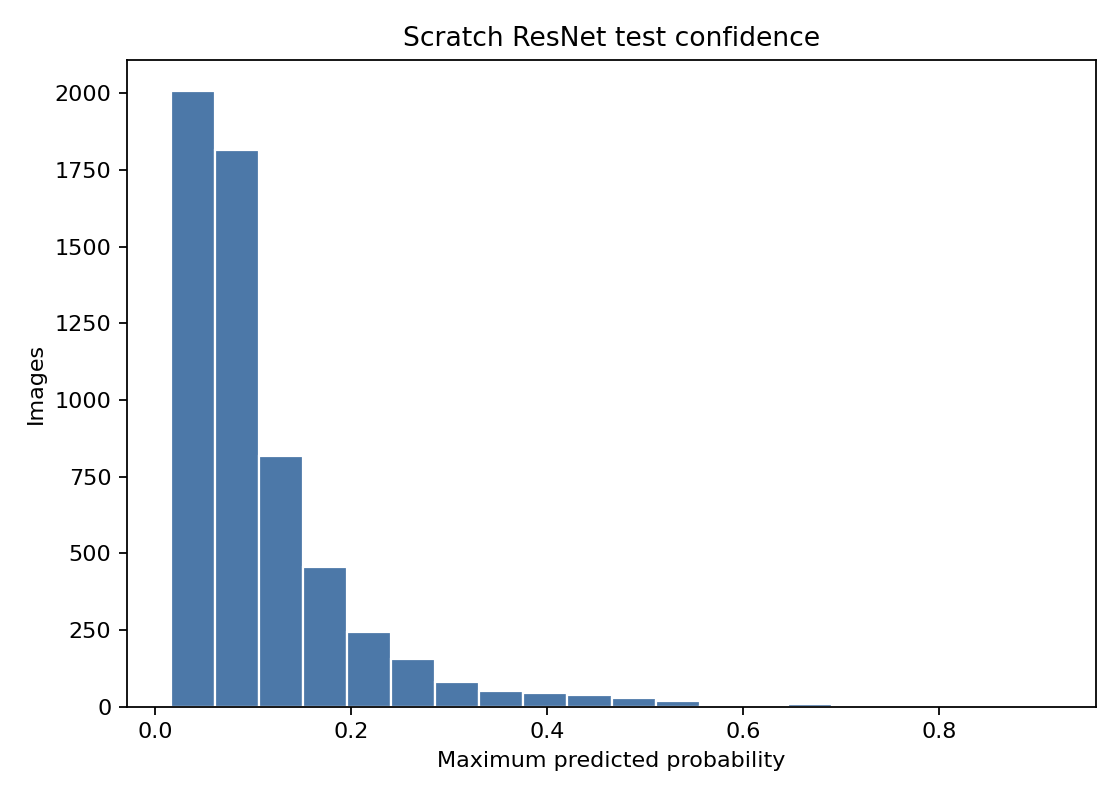

confusion_matrix_top_errors.png


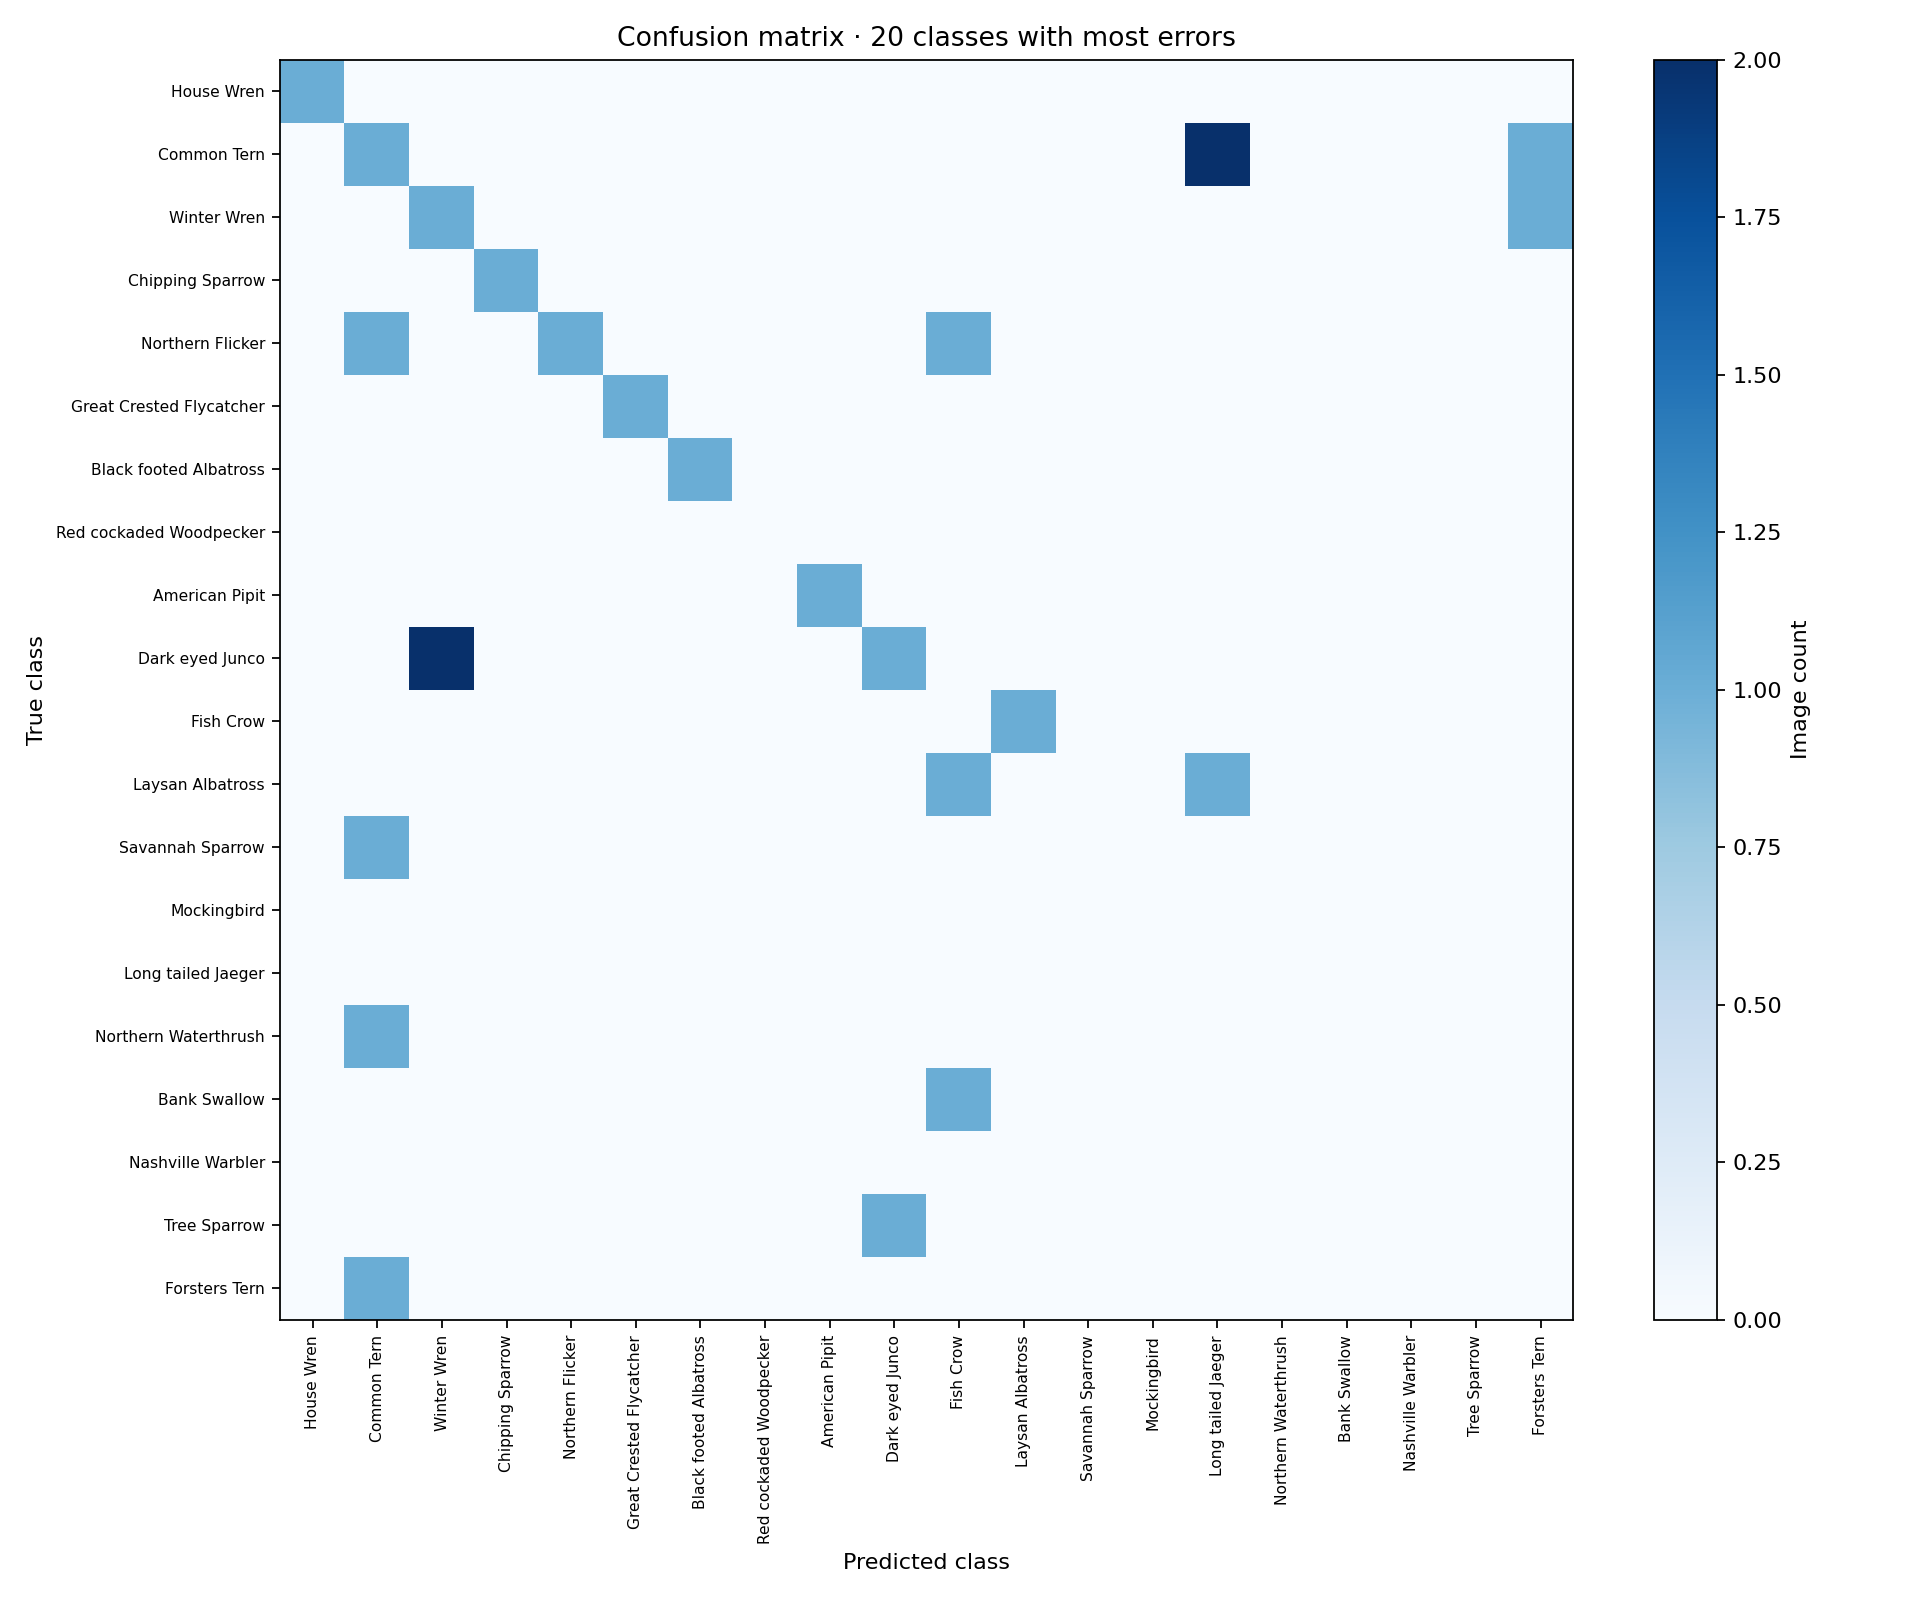

gradcam_examples.png


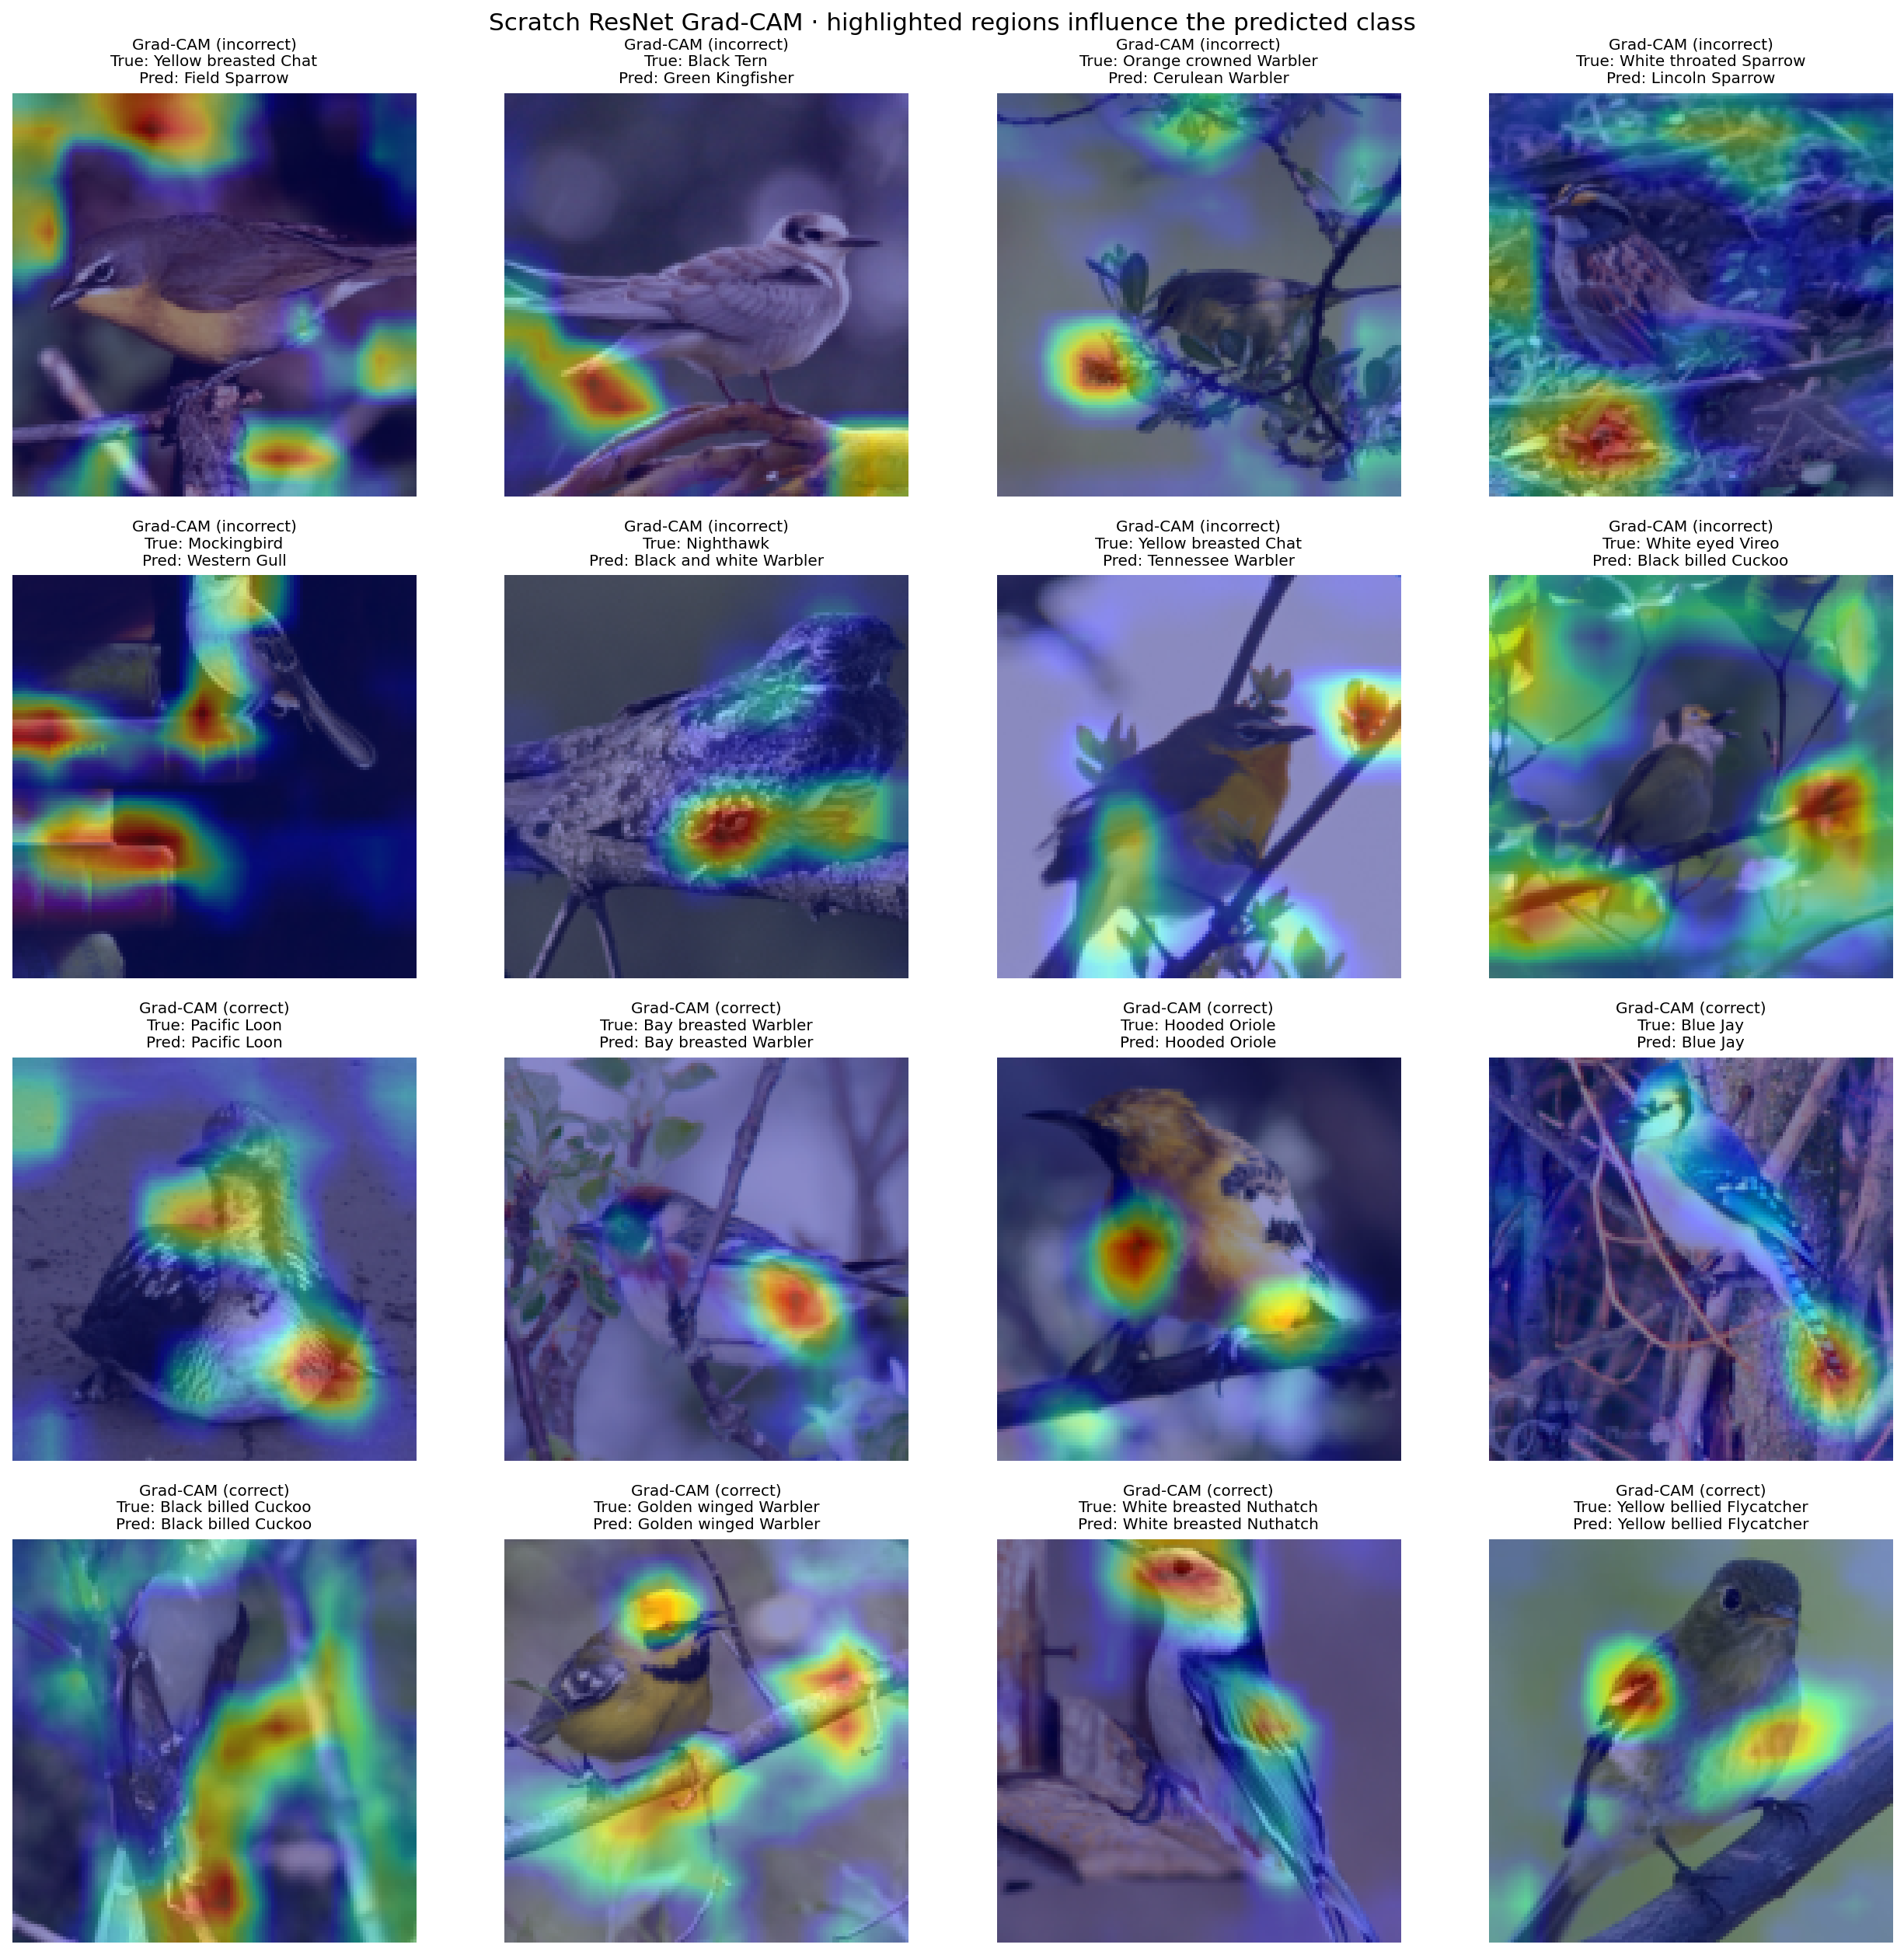

lowest_class_accuracy.png


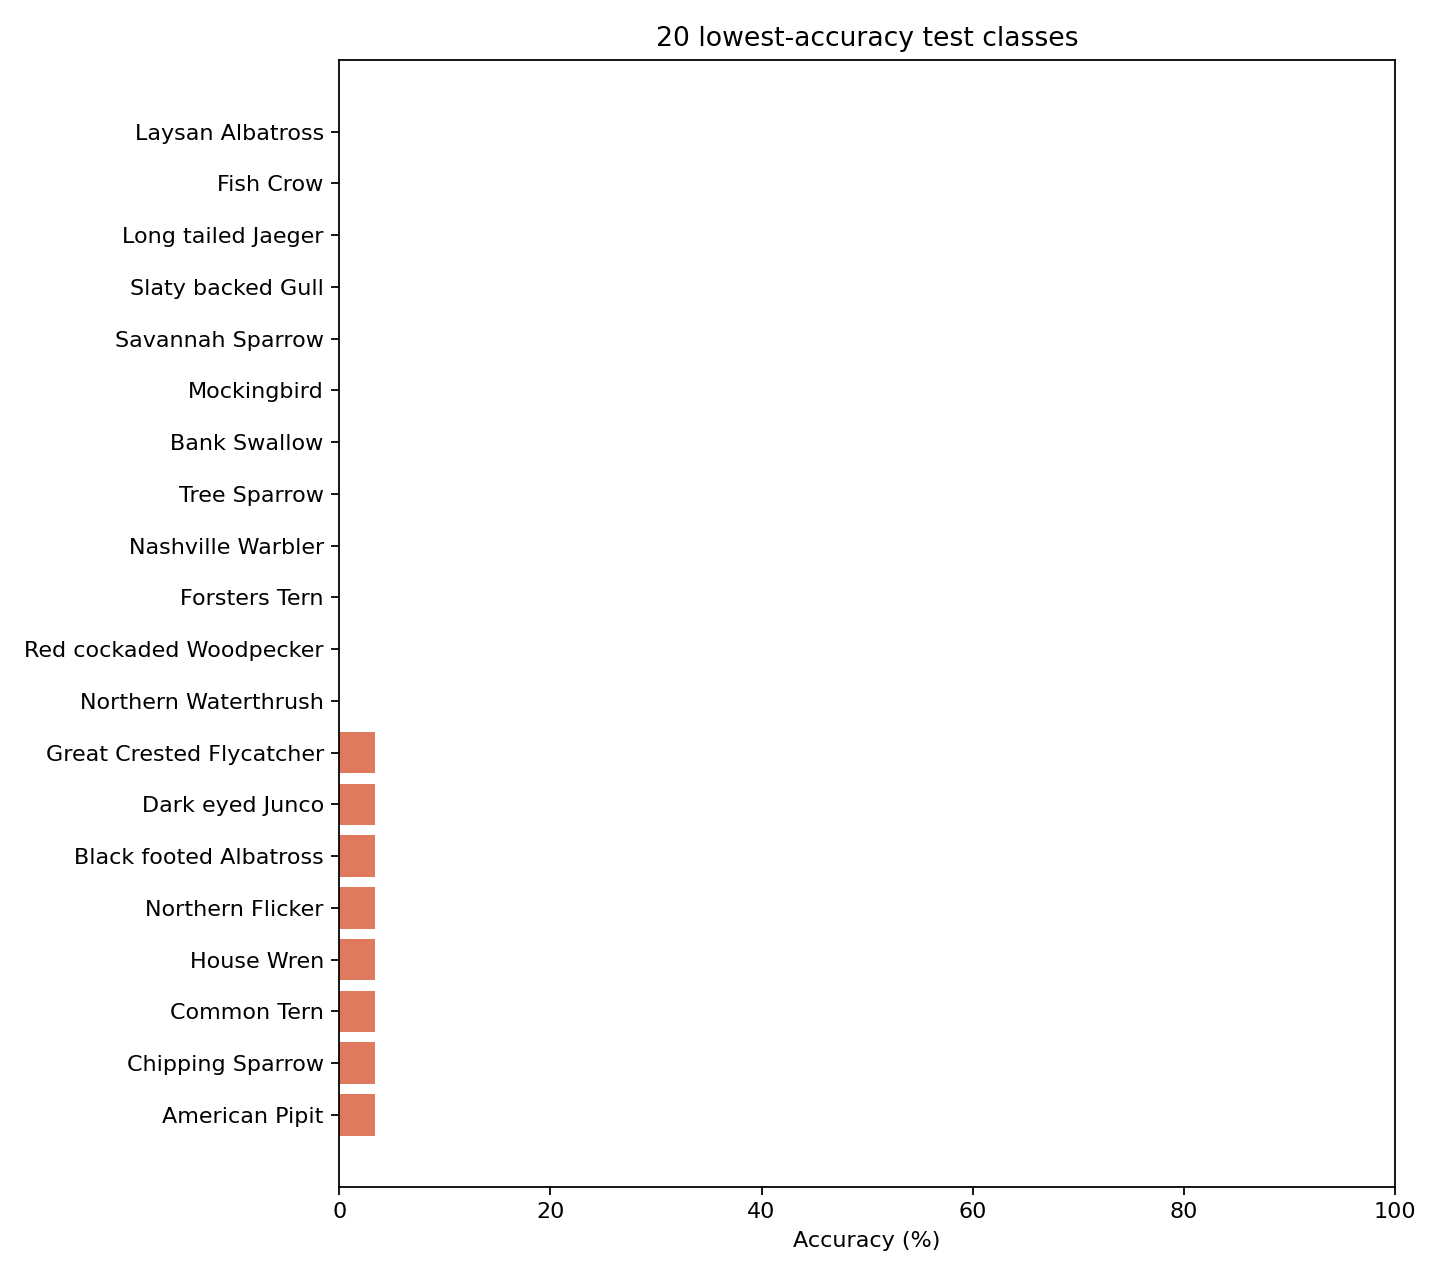

model_comparison.png


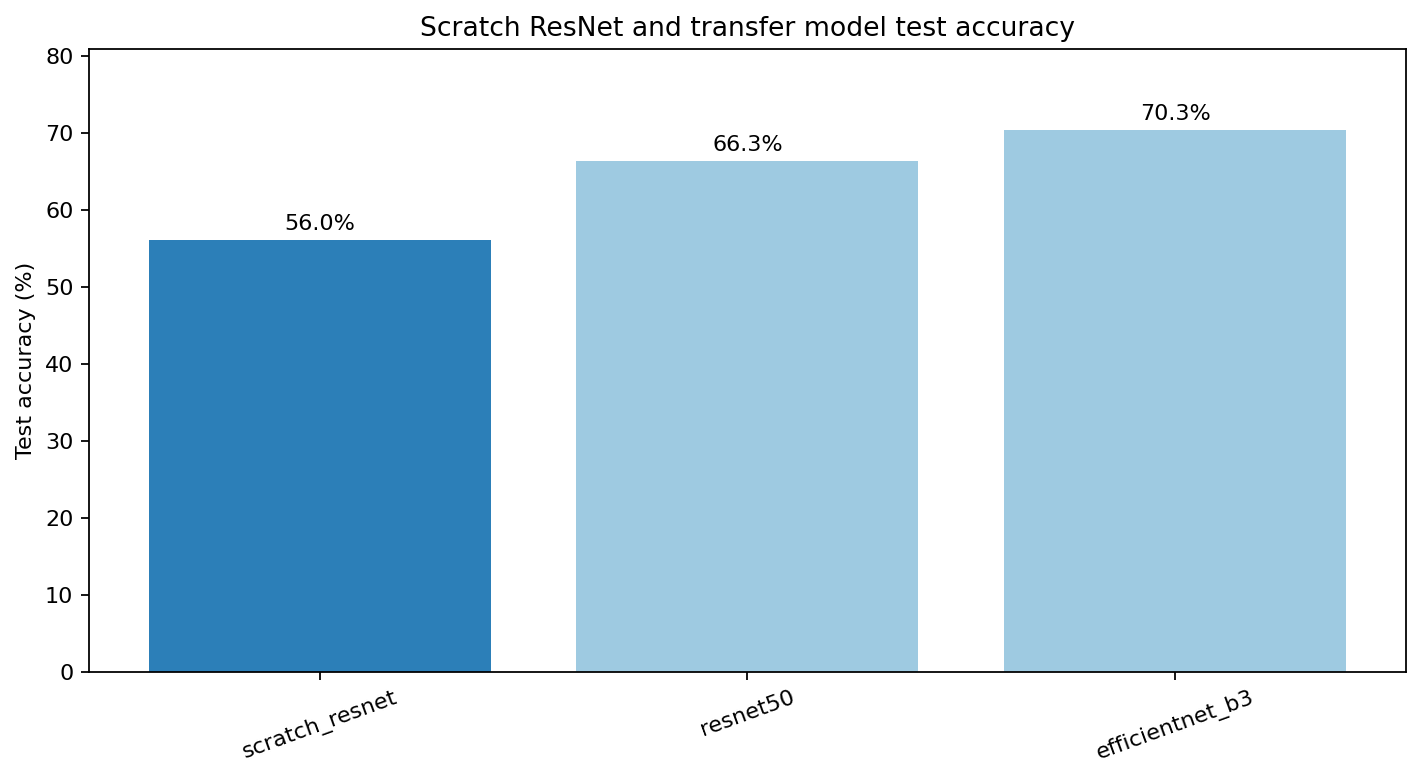

prediction_examples.png


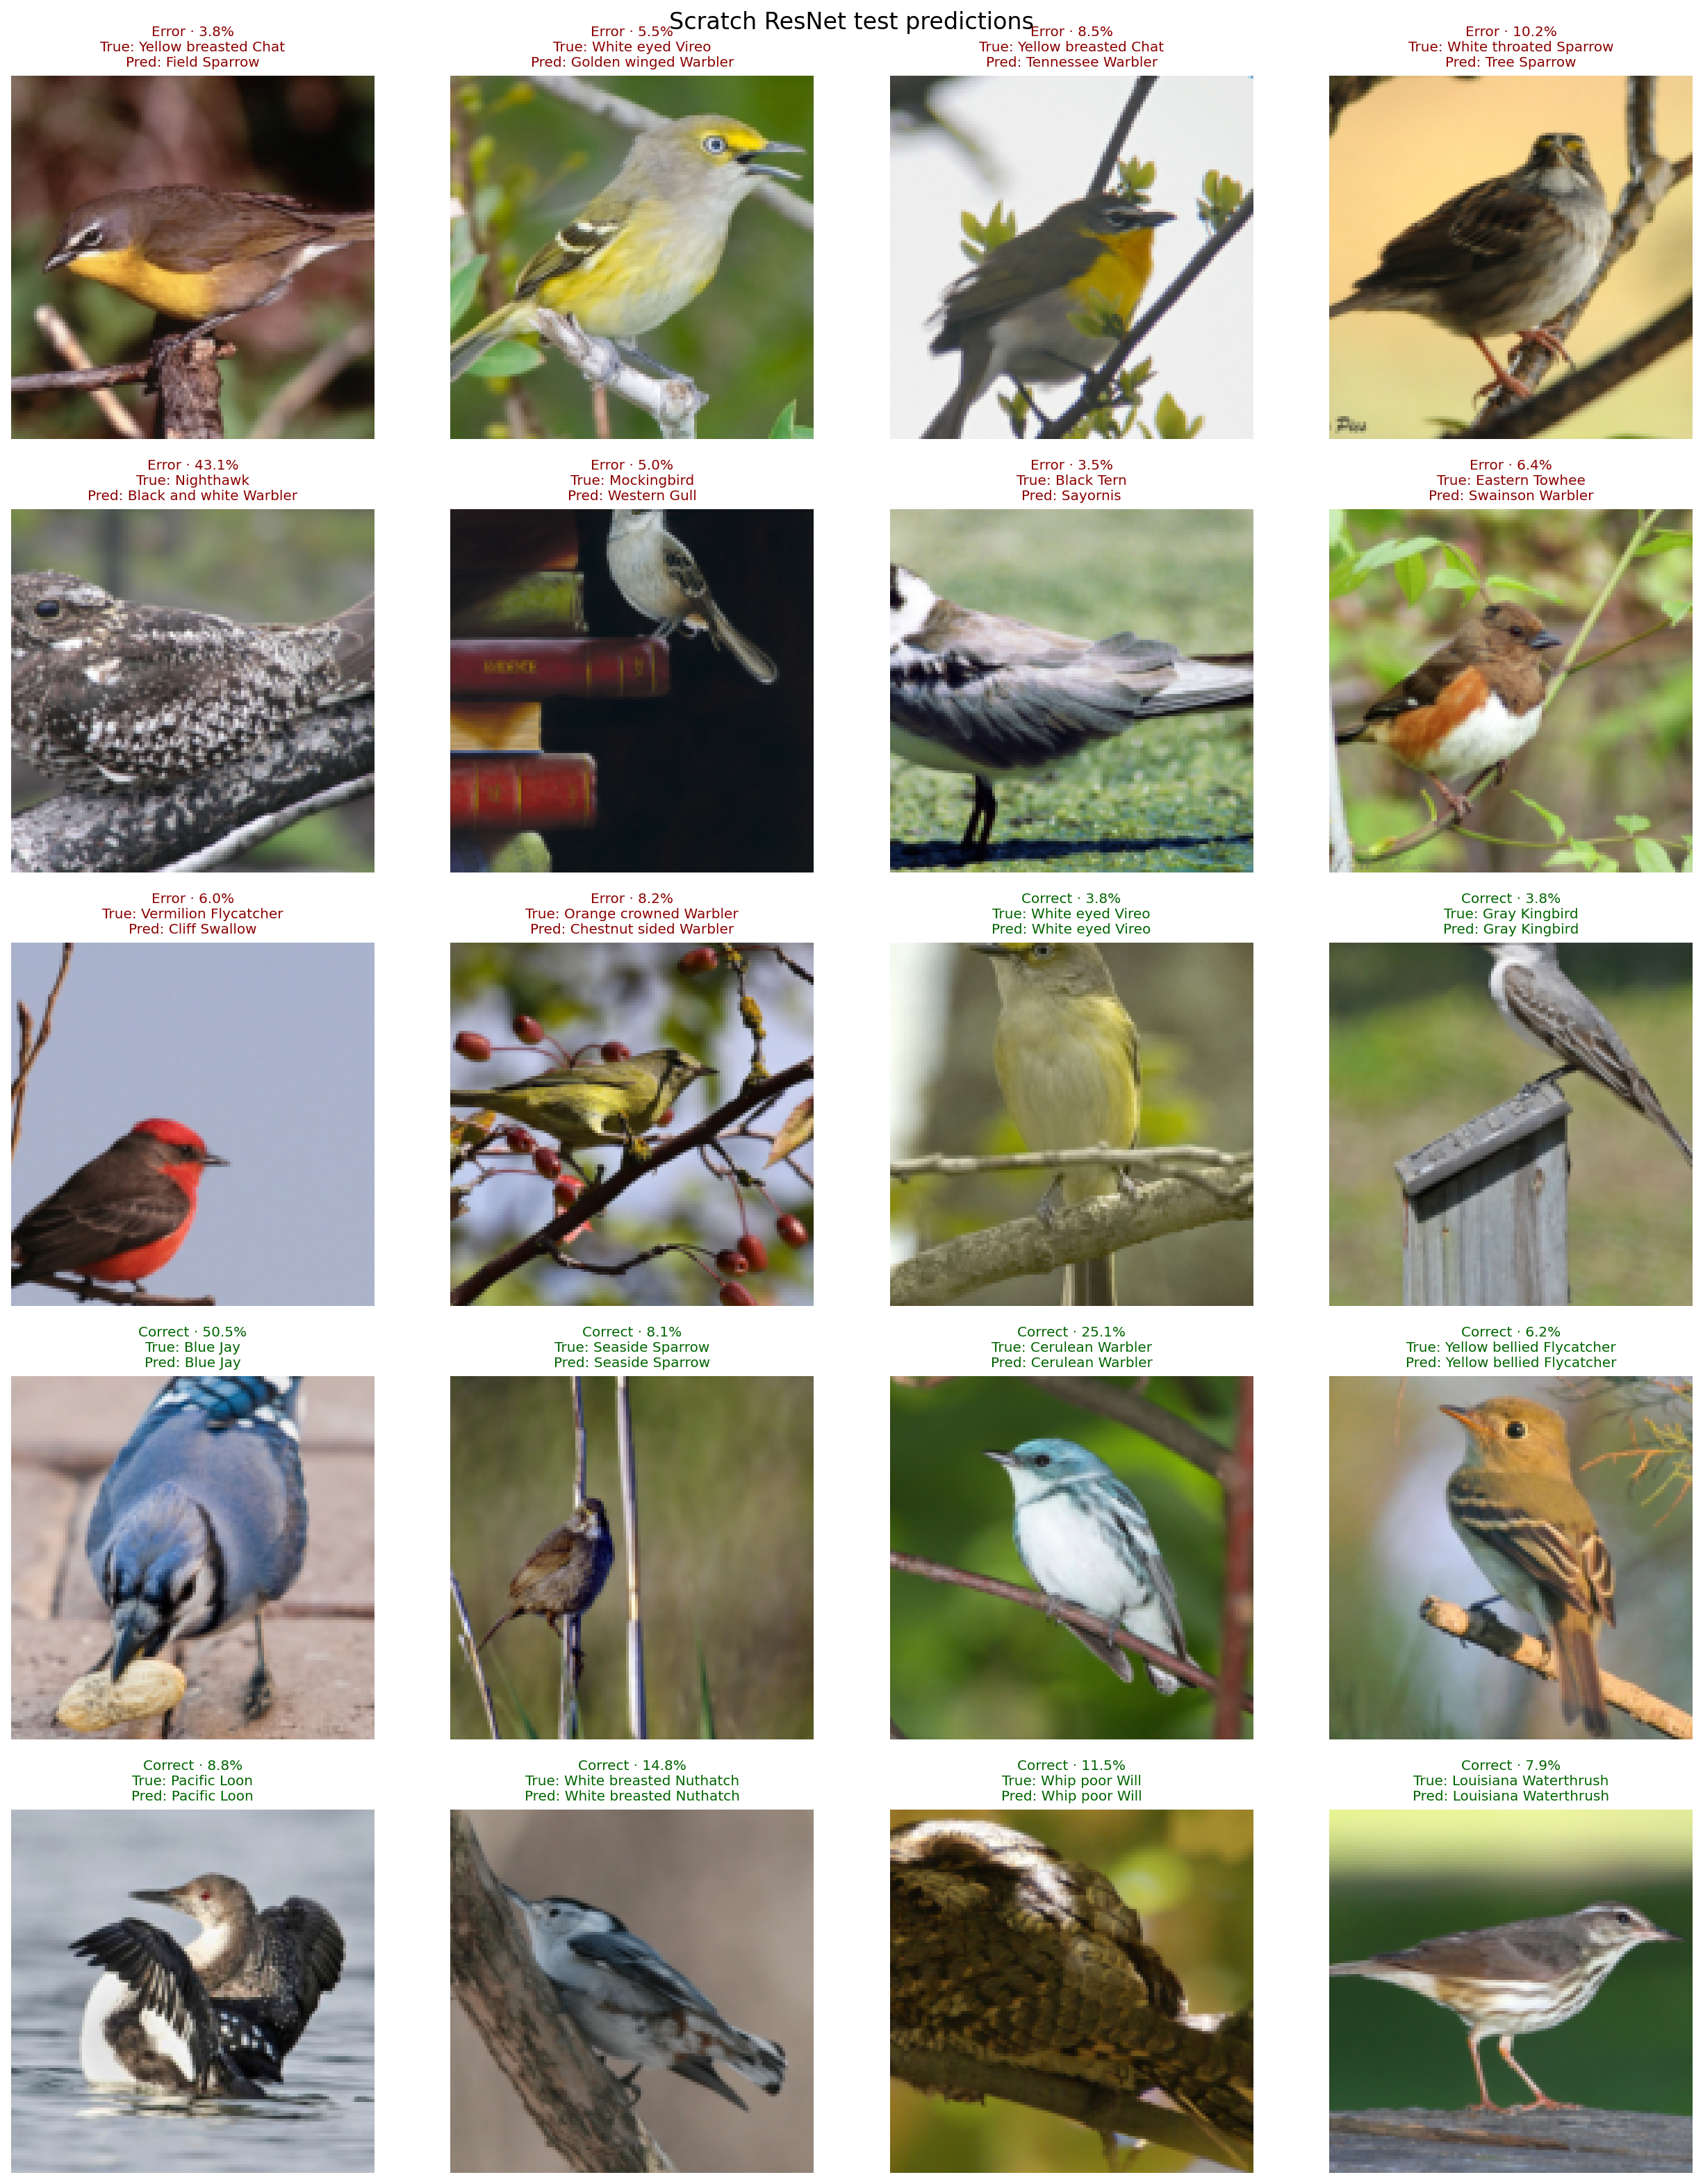

training_curves.png


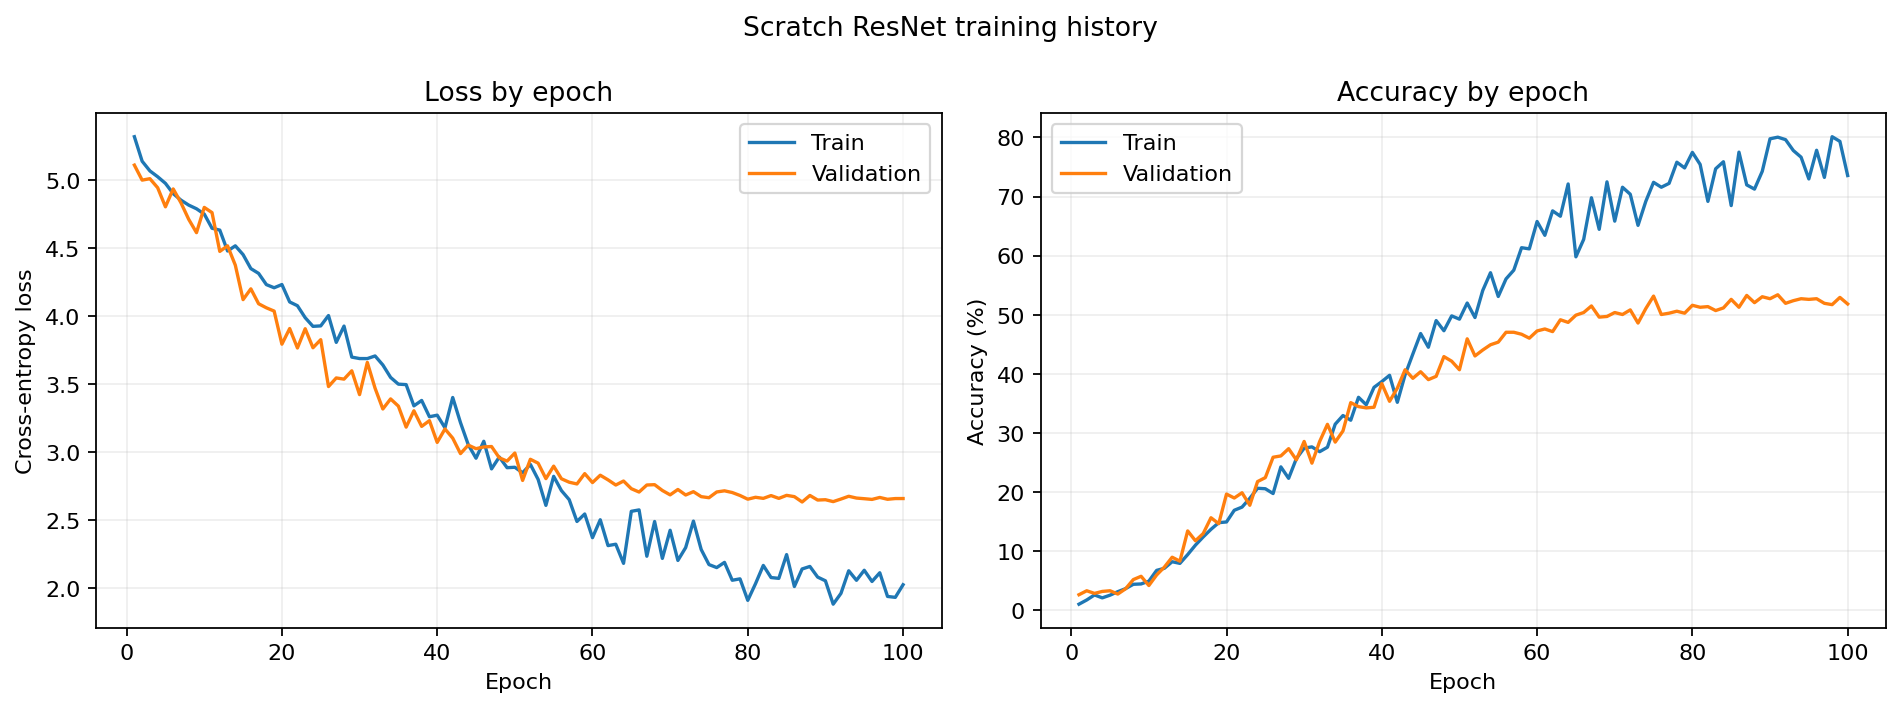

In [9]:
from IPython.display import Image, display
import os

folder = "/kaggle/working/Deep-project/outputs/scratch_resnet_visualizations"
for name in sorted(os.listdir(folder)):
    if name.endswith(".png"):
        print(name)
        display(Image(os.path.join(folder, name)))

In [11]:
from kaggle_secrets import UserSecretsClient
token = UserSecretsClient().get_secret("GH_TOKEN")

%cd /kaggle/working/Deep-project
!git config user.name "JanaHasheesh"
!git config user.email "23p0050@eng.asu.edu.eg"
!git remote set-url origin https://{token}@github.com/TokaElsaayed/Deep-project.git

/kaggle/working/Deep-project


In [12]:
!git add src/training/visualize_scratch_resnet.py
!git add outputs/scratch_resnet_visualizations
!git status

On branch main
Your branch is up to date with 'origin/main'.

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	new file:   outputs/scratch_resnet_visualizations/confidence_distribution.png
	new file:   outputs/scratch_resnet_visualizations/confusion_matrix_top_errors.png
	new file:   outputs/scratch_resnet_visualizations/evaluation_summary.json
	new file:   outputs/scratch_resnet_visualizations/gradcam_examples.png
	new file:   outputs/scratch_resnet_visualizations/lowest_class_accuracy.png
	new file:   outputs/scratch_resnet_visualizations/model_comparison.png
	new file:   outputs/scratch_resnet_visualizations/per_class_accuracy.csv
	new file:   outputs/scratch_resnet_visualizations/prediction_examples.png
	new file:   outputs/scratch_resnet_visualizations/test_predictions.csv
	new file:   outputs/scratch_resnet_visualizations/training_curves.png
	new file:   src/training/visualize_scratch_resnet.py

Untracked files:
  (use "git add <file>..." to include i

In [14]:
!rm /kaggle/working/Deep-project/visualize_scratch_resnet.py

rm: cannot remove '/kaggle/working/Deep-project/visualize_scratch_resnet.py': No such file or directory


In [15]:
!find /kaggle/working -name "visualize_scratch_resnet.py"
%cd /kaggle/working/Deep-project
!git status --short

/kaggle/working/Deep-project/src/training/visualize_scratch_resnet.py
/kaggle/working/Deep-project
A  outputs/scratch_resnet_visualizations/confidence_distribution.png
A  outputs/scratch_resnet_visualizations/confusion_matrix_top_errors.png
A  outputs/scratch_resnet_visualizations/evaluation_summary.json
A  outputs/scratch_resnet_visualizations/gradcam_examples.png
A  outputs/scratch_resnet_visualizations/lowest_class_accuracy.png
A  outputs/scratch_resnet_visualizations/model_comparison.png
A  outputs/scratch_resnet_visualizations/per_class_accuracy.csv
A  outputs/scratch_resnet_visualizations/prediction_examples.png
A  outputs/scratch_resnet_visualizations/test_predictions.csv
A  outputs/scratch_resnet_visualizations/training_curves.png
A  src/training/visualize_scratch_resnet.py


In [16]:
!git commit -m "Add scratch ResNet visualization script and outputs"
!git push origin main

[main 8d24772] Add scratch ResNet visualization script and outputs
 11 files changed, 6314 insertions(+)
 create mode 100644 outputs/scratch_resnet_visualizations/confidence_distribution.png
 create mode 100644 outputs/scratch_resnet_visualizations/confusion_matrix_top_errors.png
 create mode 100644 outputs/scratch_resnet_visualizations/evaluation_summary.json
 create mode 100644 outputs/scratch_resnet_visualizations/gradcam_examples.png
 create mode 100644 outputs/scratch_resnet_visualizations/lowest_class_accuracy.png
 create mode 100644 outputs/scratch_resnet_visualizations/model_comparison.png
 create mode 100644 outputs/scratch_resnet_visualizations/per_class_accuracy.csv
 create mode 100644 outputs/scratch_resnet_visualizations/prediction_examples.png
 create mode 100644 outputs/scratch_resnet_visualizations/test_predictions.csv
 create mode 100644 outputs/scratch_resnet_visualizations/training_curves.png
 create mode 100644 src/training/visualize_scratch_resnet.py
remote: Permis

In [17]:
from kaggle_secrets import UserSecretsClient
token = UserSecretsClient().get_secret("GH_TOKEN")

%cd /kaggle/working/Deep-project
!git remote set-url origin https://{token}@github.com/TokaElsaayed/Deep-project.git
!git push origin main

/kaggle/working/Deep-project
Enumerating objects: 21, done.
Counting objects: 100% (21/21), done.
Delta compression using up to 4 threads
Compressing objects: 100% (17/17), done.
Writing objects: 100% (17/17), 2.29 MiB | 5.14 MiB/s, done.
Total 17 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/TokaElsaayed/Deep-project.git
   eedddff..8d24772  main -> main
